# TT-26 — CNN: sàng lọc viêm phổi trên ảnh X-quang ngực

**Bài toán.** Bệnh viện tuyến huyện không có bác sĩ chẩn đoán hình ảnh trực đêm. Cần công cụ **sàng lọc**: gắn cờ phim
nghi viêm phổi để bác sĩ trực đọc trước. Bỏ sót một ca viêm phổi ở trẻ em nguy hiểm hơn nhiều so với một lần báo động
giả, nên **recall lớp PNEUMONIA là metric chính** (yêu cầu ≥ 0,97 trên val, ≥ 0,96 trên test). Mọi con số phải kèm
**số ca bỏ sót**.

**Câu hỏi chính:** CNN tự xây train từ đầu, Transfer Learning (EfficientNetB0 đóng băng) và Fine-tuning khác nhau thế
nào, và model có nhìn vào **vùng phổi** khi ra quyết định không?

> 🩺 Đây là công cụ **sắp thứ tự ưu tiên đọc phim**, không phải công cụ chẩn đoán. Mọi phim đều phải có bác sĩ đọc.

**Cách chạy.** Notebook gọi các hàm trong `src/`. Mỗi lần train lưu checkpoint + lịch sử + dự đoán vào `models/runs/`,
nên chạy lại notebook **đọc lại** kết quả thay vì train lại (~2 giờ trên CPU). Muốn train lại: đặt `TT26_RETRAIN=1`.

In [1]:
%matplotlib inline
import os, sys, warnings
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Image, display

import data_pipeline as D
import model as M
import train as T

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)
R = T.REPORTS_DIR
print("TensorFlow", tf.__version__, "| thiet bi:", [d.device_type for d in tf.config.list_physical_devices()])

TensorFlow 2.21.0 | thiet bi: ['CPU']


## 1–2. Đếm ảnh và tự tách lại tập validation

**Logic code (`data_pipeline.load_index` → `resplit`):**

```python
# Lan dau: doc 5.856 JPEG, chuyen xam, resize 224x224 -> data/cache_224.npz (uint8, 294 MB)
df["benh_nhan"] = patient_id(file)            # person123_bacteria_4.jpeg -> "P-person123"
pool = train_goc + val_goc                     # 5.216 + 16 anh
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
_, val_idx = next(sgkf.split(pool, pool.y, groups=pool.benh_nhan))   # ~1/7 = 14,3% lam val
```

* `Stratified`: giữ tỉ lệ NORMAL/PNEUMONIA ở val bằng train.
* `Group` theo **bệnh nhân**: một bệnh nhân có thể có tới 31 phim. Nếu phim của cùng một người nằm ở cả train và val,
  model chỉ cần "nhận ra người" là đoán đúng, và val sẽ đẹp giả tạo.
* Tập test gốc (624 ảnh) **giữ nguyên** và chỉ dùng ở bước 10.

[load] 5,856 anh | train/val/test = 4,484/748/624


Tap GOC cua Kaggle:


lop,NORMAL,PNEUMONIA,tong,ti_le_PNEUMONIA,so_benh_nhan
tap_goc,,,,,
train,1341,3875,5216,0.7429,2846
val,8,8,16,0.5000,15
test,234,390,624,0.6250,427


Sau khi tach lai:


,so_anh,NORMAL,PNEUMONIA,so_benh_nhan,ti_le_PNEUMONIA
tap,,,,,
train,4484,1156,3328,2452,0.7422
val,748,193,555,409,0.7420
test,624,234,390,427,0.6250


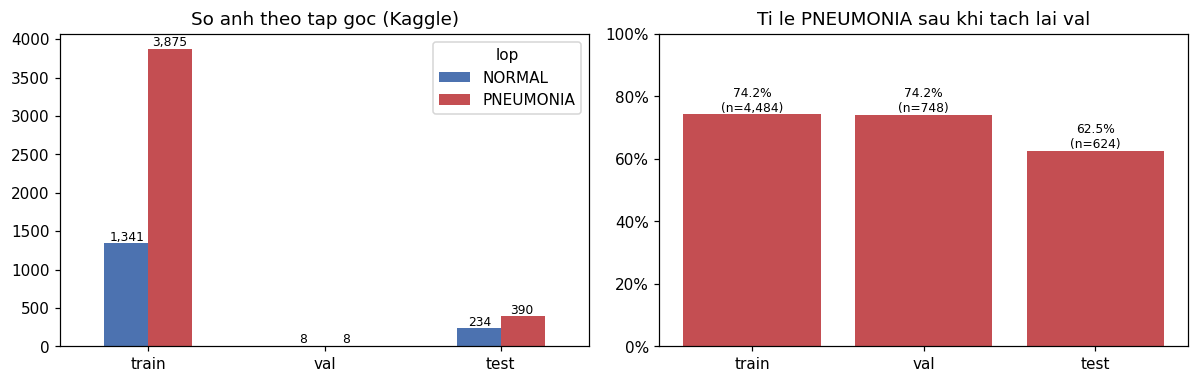

In [2]:
data = T.load()
counts = T.run_counts(data)
print("Tap GOC cua Kaggle:"); display(counts)
print("Sau khi tach lai:"); display(pd.read_csv(R / "chia_du_lieu.csv", index_col=0))
display(Image(R / "so_luong_anh.png"))

**Đọc kết quả: đủ cả 3 vấn đề của đề bài.**

| Vấn đề | Số liệu | Cách xử lý |
|---|---|---|
| 1. Val gốc quá nhỏ | **16 ảnh** (8 + 8). Một ảnh đoán sai làm recall đổi 12,5 điểm | Gộp vào train rồi tách lại: val mới **748 ảnh** (193 NORMAL / 555 PNEUMONIA), 409 bệnh nhân |
| 2. Mất cân bằng | Train 1.156 NORMAL / 3.328 PNEUMONIA (**74,2%**) | `class_weight` balanced: NORMAL **1,94**, PNEUMONIA **0,67** |
| 3. Train ≠ test | Test chỉ **62,5%** PNEUMONIA | Không sửa được. Phải nêu trong báo cáo (bước 10 cho thấy hậu quả) |

Train / val mới có tỉ lệ PNEUMONIA giống hệt nhau (74,2%) nhờ stratify, và không có bệnh nhân nào nằm ở cả hai tập
(`load()` có `assert` kiểm tra).

## 3. Quan sát ảnh bằng mắt

**Logic code (`show_samples`):** chọn ngẫu nhiên 8 ảnh mỗi lớp từ tập train (seed 42), ghi tác nhân (vi khuẩn / virus)
lấy từ tên file.

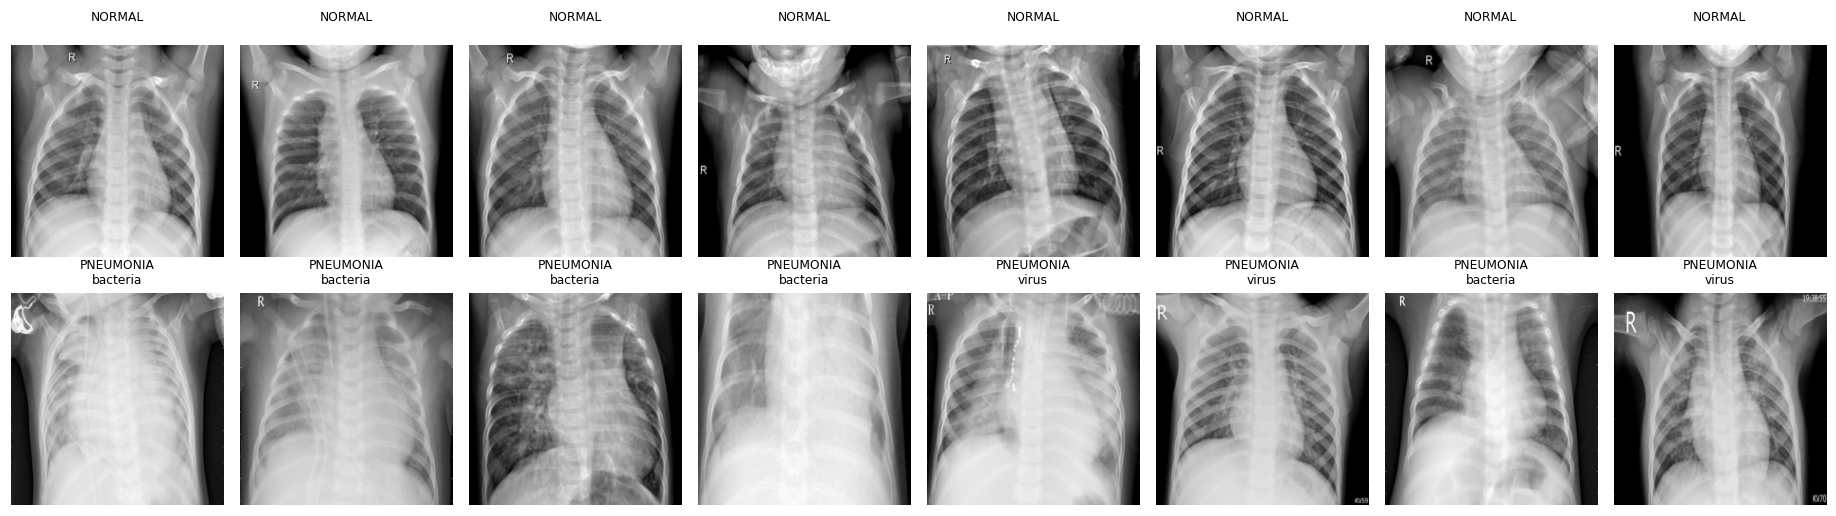

In [3]:
T.show_samples(data)
display(Image(R / "mau_anh.png"))

**Đọc kết quả:**

* **NORMAL**: hai phế trường tối (khí), thấy rõ mạch máu và bờ tim, góc sườn hoành nhọn.
* **PNEUMONIA do vi khuẩn**: thường có một vùng mờ đặc (đông đặc) khu trú, đôi khi mờ gần hết một bên phổi.
* **PNEUMONIA do virus**: mờ lan toả dạng lưới hai bên, khó thấy hơn. Đây là nhóm dễ nhầm với NORMAL.
* ⚠️ **Đường tắt tiềm năng:** phim PNEUMONIA có nhiều chữ/ký hiệu hơn (giờ chụp, mã máy `KV70`, dây điện cực, ống),
  đặc biệt ở **góc ảnh**. Phim NORMAL thường chỉ có chữ "R". Model có thể học nhận ra những thứ này thay vì tổn thương
  phổi, nên bước 11 (Grad-CAM) là bắt buộc.

## 4. tf.data pipeline và augmentation

**Logic code (`data_pipeline.make_dataset`, `augmenter`):**

```python
ds = Dataset.from_tensor_slices((anh_uint8, y)).shuffle(...).batch(32)
ds = ds.map(lambda x, y: (aug(to_rgb(x), training=True), y))   # CHI tap train
# augmenter: RandomRotation(10/360) + RandomTranslation(0.1) + RandomZoom(0.1)
#            + RandomBrightness(0.1) + RandomContrast(0.1)   -- KHONG co RandomFlip
```

* **Resize 224×224** làm 1 lần khi tạo cache. Ảnh xám được lặp thành 3 kênh vì EfficientNet học trên ảnh màu.
* **Chuẩn hoá nằm trong model**: EfficientNetB0 của Keras có sẵn lớp `Rescaling` + `Normalization` (nhận 0..255), CNN tự
  xây có `Rescaling(1/255)`. File `.keras` vì vậy tự đủ, không cần lưu thêm bước tiền xử lý.
* **Không lật ngang**: tim nằm bên trái bệnh nhân. Lật ngang tạo ra ảnh *dextrocardia* (tim bên phải), một dị tật hiếm,
  nên model học trên phân phối sai. Lật dọc thì vô nghĩa với phim chụp thẳng đứng.
* Val và test **không** augmentation.

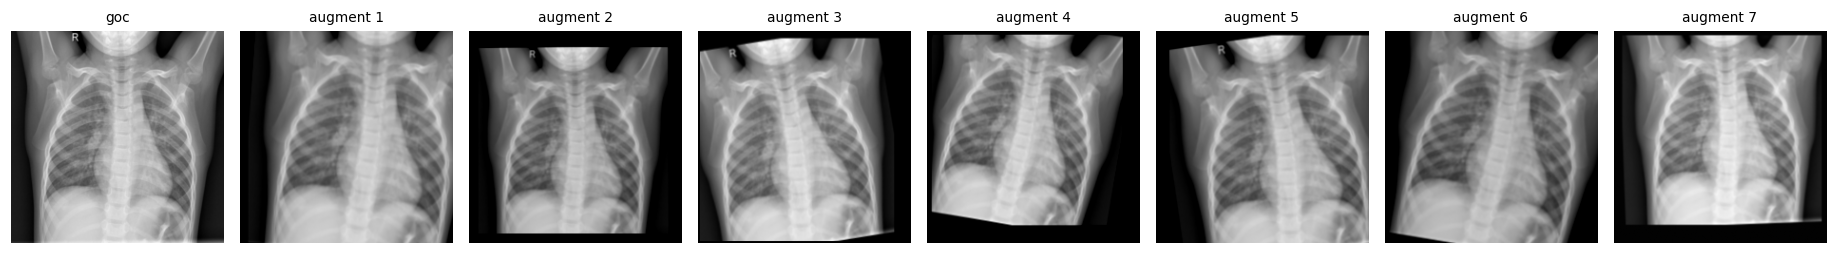

In [4]:
T.show_augmentation(data)
display(Image(R / "augmentation.png"))

**Đọc kết quả:** 7 bản biến đổi đều vẫn là một phim X-quang hợp lý: nghiêng nhẹ, dịch, phóng to/thu nhỏ, sáng/tối hơn
một chút. Chữ **"R"** (đánh dấu bên phải bệnh nhân) luôn ở góc trên **trái** ảnh và bóng tim luôn lệch về phía **phải**
ảnh (= bên trái bệnh nhân). Không bản nào bị lật.

## Hàm huấn luyện dùng chung: `fit_run`

Mọi mô hình đều đi qua một hàm, nên chỉ khác nhau ở đúng thứ đang so sánh:

```python
tf.keras.utils.set_random_seed(42)
model = M.compile_model(build(), lr)   # Adam + binary_crossentropy, metric: Recall, Precision, AUC
model.fit(train_ds, validation_data=val_ds, epochs=..., class_weight={0: 1.94, 1: 0.67},
          callbacks=[EarlyStopping("val_auc", restore_best_weights=True),
                     ReduceLROnPlateau("val_loss", factor=0.3, patience=2),
                     ModelCheckpoint("models/runs/<ten>.keras", "val_auc", save_best_only=True)])
```

* **Theo dõi `val_auc` (ROC-AUC)**, không theo dõi `val_recall`: recall ở ngưỡng 0,5 có thể đạt 1,0 chỉ bằng cách đoán
  tất cả là PNEUMONIA. AUC đo chất lượng **xếp hạng**, còn ngưỡng để đạt recall 0,97 sẽ chọn riêng ở bước 9.
* Kết quả (checkpoint, `history_<ten>.csv`, xác suất val/test) được lưu lại. Lần chạy sau đọc lại.

## 5. Baseline: CNN nhỏ train từ đầu

**Logic code (`model.build_small_cnn`):**

```python
x = Rescaling(1/255)(anh)                                     # 224x224x3
for f in (32, 64, 128):                                       # 3 khoi Conv
    x = Conv2D(f, 3, strides=2 neu la conv dau tien) -> BN -> ReLU
    x = Conv2D(f, 3) -> BN -> ReLU
    x = MaxPooling2D(2)
# 224 -> 112 (conv buoc 2) -> 56 -> 28 -> 14 : ban do dac trung 14x14x128
x = GlobalAveragePooling2D -> Dropout(0.3) -> Dense(1, sigmoid)
```

288.481 tham số, ít hơn EfficientNetB0 14 lần. Conv đầu tiên dùng **bước 2** vì trên CPU, chạy 2 Conv ở độ phân giải
224×224 đầy đủ chậm gấp 5 lần (6 so với 30 ảnh/giây). lr 1e-3, tối đa 20 epoch, EarlyStopping patience 5.

In [5]:
runs = {"cnn_tu_dau": T.run_scratch(data)}
r = runs["cnn_tu_dau"]
print(f"{r['so_epoch']} epoch, tot nhat epoch {r['epoch_tot_nhat']}, {r['thoi_gian_train_s']/60:.0f} phut, "
      f"{r['tham_so']:,} tham so")
r["history"][["epoch", "loss", "auc", "val_loss", "val_auc", "val_recall", "learning_rate"]]

[cnn_tu_dau] doc lai ket qua da train (cnn_tu_dau.keras)


20 epoch, tot nhat epoch 18, 57 phut, 288,481 tham so


,epoch,loss,auc,val_loss,val_auc,val_recall,learning_rate
0,1,0.3481,0.9234,1.9687,0.5000,1.0000,0.0010
1,2,0.2746,0.9526,1.4316,0.6779,1.0000,0.0010
2,3,0.2181,0.9710,3.0374,0.5000,1.0000,0.0010
3,4,0.2089,0.9732,1.0233,0.8590,1.0000,0.0010
4,5,0.2219,0.9689,0.2449,0.9737,0.9838,0.0010
5,6,0.2020,0.9743,1.6117,0.5967,1.0000,0.0010
6,7,0.1705,0.9817,0.1688,0.9827,0.9874,0.0010
7,8,0.1912,0.9770,5.6544,0.5000,1.0000,0.0010
8,9,0.1525,0.9853,0.2131,0.9853,0.9946,0.0010
9,10,0.1472,0.9865,0.5912,0.9609,0.6306,0.0003


**Đọc kết quả:**

* Val **rất bất ổn** trong 11 epoch đầu: `val_auc` nhảy 0,50 → 0,97 → 0,60 → 0,98 → **0,50**, `val_loss` có lúc lên 5,65.
  `val_auc = 0,50` nghĩa là model cho **cùng một xác suất** cho mọi ảnh val (bão hoà về 1). Trong khi đó loss train giảm
  đều. Nguyên nhân: **BatchNorm**. Khi train, BN dùng trung bình/phương sai của từng batch. Khi đánh giá, BN dùng trung
  bình trượt tích luỹ. Với learning rate 1e-3, trọng số đổi nhanh hơn trung bình trượt kịp cập nhật, nên lúc đánh giá
  các lớp nhận phân phối lệch.
* Từ epoch 10, `ReduceLROnPlateau` hạ lr xuống 3e-4 → 9e-5 → 2,7e-5. Val ổn định ở **AUC 0,995**, tốt nhất ở epoch 18.
* **Không overfit** dù train từ đầu với 4.484 ảnh: loss train 0,10 và loss val 0,11 gần nhau. Augmentation + BN +
  Dropout + GlobalAveragePooling (không có lớp Dense lớn) đủ giữ mạng 288k tham số không học thuộc.
* Tốn **57 phút** (20 epoch × ~2,8 phút), lâu nhất trong các mô hình.

## 6. Transfer Learning giai đoạn 1: đóng băng EfficientNetB0

**Logic code (`model.build_transfer`):**

```python
base = EfficientNetB0(include_top=False, weights="imagenet")   # 4,05 trieu tham so, hoc tren 1,2 trieu anh
base.trainable = False
x = base(anh, training=False)      # BatchNorm cua base LUON o che do suy luan
x = GlobalAveragePooling2D -> Dropout(0.3) -> Dense(1, sigmoid)
```

Chỉ **1.281 tham số** được train (1.280 trọng số + 1 bias của lớp cuối). lr 1e-3, tối đa 12 epoch.

In [6]:
runs["tl_dong_bang"] = T.run_transfer(data)
r = runs["tl_dong_bang"]
print(f"{r['so_epoch']} epoch, tot nhat epoch {r['epoch_tot_nhat']}, {r['thoi_gian_train_s']/60:.0f} phut, "
      f"train {r['tham_so_train_duoc']:,} / {r['tham_so']:,} tham so")
r["history"][["epoch", "loss", "auc", "val_loss", "val_auc", "val_recall", "learning_rate"]]

[tl_dong_bang] doc lai ket qua da train (tl_dong_bang.keras)


12 epoch, tot nhat epoch 12, 28 phut, train 1,281 / 4,050,852 tham so


,epoch,loss,auc,val_loss,val_auc,val_recall,learning_rate
0,1,0.4097,0.9111,0.3376,0.9717,0.8216,0.0010
1,2,0.2527,0.9676,0.2551,0.9772,0.8541,0.0010
2,3,0.2151,0.9745,0.2195,0.9814,0.8757,0.0010
3,4,0.2014,0.9778,0.2099,0.9830,0.8793,0.0010
4,5,0.1862,0.9804,0.1858,0.9840,0.9045,0.0010
5,6,0.1805,0.9806,0.2037,0.9844,0.8811,0.0010
6,7,0.1639,0.9846,0.1709,0.9849,0.9207,0.0010
7,8,0.1668,0.9834,0.1617,0.9850,0.9387,0.0010
8,9,0.1591,0.9852,0.1802,0.9859,0.9135,0.0010
9,10,0.1539,0.9857,0.1680,0.9867,0.9243,0.0010


**Đọc kết quả:**

* **Rất ổn định**: `val_auc` tăng đơn điệu 0,972 → 0,987. Ngay epoch 1 đã đạt 0,972, vì đặc trưng ImageNet (cạnh, kết
  cấu, vùng sáng/tối) đã đủ tách phần lớn ca.
* Nhưng **trần thấp hơn CNN từ đầu** (0,987 so với 0,995). Đặc trưng học trên ảnh chó, mèo, xe cộ không phải đặc trưng
  tốt nhất cho phim X-quang xám. Với 1.281 tham số, mô hình chỉ có thể *chọn* trong 1.280 đặc trưng có sẵn.
* Train AUC ≈ val AUC (0,985 / 0,987): không overfit, đúng như mong đợi khi gần như mọi thứ bị đóng băng.

## 7. Fine-tuning giai đoạn 2 (lr 1e-5) và đối chứng lr 1e-3

**Logic code (`model.unfreeze_top`, `train._from_frozen`):**

```python
model = load_model("models/runs/tl_dong_bang.keras")   # xuat phat tu trong so TOT NHAT cua giai doan 1
base.trainable = True
for layer in base.layers[:-30]:  layer.trainable = False    # chi mo 30/238 lop cuoi (block6d, block7a, top)
for layer in base.layers[-30:]:
    if isinstance(layer, BatchNormalization): layer.trainable = False   # BN giu thong ke ImageNet
compile(Adam(1e-5))        # nho hon giai doan 1 100 lan
```

Mở khoá 1,48 triệu tham số. Để kiểm chứng cạm bẫy "fine-tune với lr lớn phá huỷ trọng số ImageNet", chạy thêm một
**đối chứng**: cùng điểm xuất phát, cùng 30 lớp, nhưng lr 1e-3, 4 epoch. Đối chứng **không** tham gia chọn mô hình.

In [7]:
runs["tl_finetune"] = T.run_finetune(data, runs["tl_dong_bang"])
runs["tl_finetune_lr_lon"] = T.run_finetune_lr_lon(data, runs["tl_dong_bang"])
for k in ["tl_finetune", "tl_finetune_lr_lon"]:
    r = runs[k]
    print(f"{T.NAMES[k]}: {r['so_epoch']} epoch, tot nhat epoch {r['epoch_tot_nhat']}, {r['thoi_gian_train_s']/60:.0f} phut")
    display(r["history"][["epoch", "loss", "auc", "val_loss", "val_auc", "val_recall", "learning_rate"]])

[tl_finetune] doc lai ket qua da train (tl_finetune.keras)


[tl_finetune_lr_lon] doc lai ket qua da train (tl_finetune_lr_lon.keras)


EfficientNetB0 fine-tune (lr 1e-5): 12 epoch, tot nhat epoch 9, 34 phut


,epoch,loss,auc,val_loss,val_auc,val_recall,learning_rate
0,1,0.1472,0.9868,0.1799,0.9878,0.9045,0.0000
1,2,0.1489,0.9861,0.1637,0.9886,0.9171,0.0000
2,3,0.1385,0.9875,0.1208,0.9878,0.9622,0.0000
3,4,0.1332,0.9888,0.1484,0.9895,0.9261,0.0000
4,5,0.1258,0.9900,0.1477,0.9899,0.9315,0.0000
5,6,0.1199,0.9907,0.1553,0.9898,0.9207,0.0000
6,7,0.1148,0.9915,0.1428,0.9902,0.9351,0.0000
7,8,0.1081,0.9928,0.1487,0.9902,0.9261,0.0000
8,9,0.1174,0.9914,0.1400,0.9904,0.9369,0.0000
9,10,0.1130,0.9918,0.1419,0.9903,0.9351,0.0000


EfficientNetB0 fine-tune lr 1e-3 (doi chung): 4 epoch, tot nhat epoch 2, 6 phut


,epoch,loss,auc,val_loss,val_auc,val_recall,learning_rate
0,1,0.2500,0.9701,0.4067,0.9799,0.8396,0.0010
1,2,0.1319,0.9884,0.2304,0.9900,0.8973,0.0010
2,3,0.1139,0.9917,0.1343,0.9835,0.9550,0.0010
3,4,0.1047,0.9925,0.1989,0.9867,0.9261,0.0010


**Đọc kết quả:**

* **Fine-tune lr 1e-5:** `val_auc` 0,987 → **0,990** (epoch 9). Tăng thêm 0,003, ổn định, không phá gì. Train AUC lên
  0,993 (cao hơn val 0,990): bắt đầu khớp train hơn val một chút, nhưng chưa phải overfit nặng.
* **Đối chứng lr 1e-3:** ngay epoch đầu, `val_loss` nhảy từ 0,17 lên **0,41** và `val_recall` tụt xuống 0,84. Đây là cú
  sốc đề bài cảnh báo: bước cập nhật lớn làm lệch trọng số đã học. Sau đó mô hình **hồi phục** (val_auc 0,990 ở epoch
  2) rồi dao động (0,984, 0,987).
* Vậy ở bài này lr 1e-3 **không phá huỷ hoàn toàn**, vì chỉ mở 30/238 lớp (từ `block6d_expand_bn` trở đi) và BatchNorm vẫn bị khoá. Nhưng đường học
  giật và không đáng tin. Không ai biết trước epoch nào là epoch "may mắn". Với lr 1e-5 thì đường học mượt.

## 8. Learning curves cả hai giai đoạn

**Logic code (`plot_learning_curves`):** hàng trên là CNN từ đầu. Hàng dưới là giai đoạn 1 (epoch 1–12) nối tiếp
giai đoạn 2 (epoch 13+), bắt đầu từ điểm tốt nhất của giai đoạn 1. Đường nét đứt là đối chứng lr 1e-3. Đường chấm dọc
đánh dấu epoch tốt nhất (hàng trên) hoặc chỗ chuyển giai đoạn (hàng dưới).

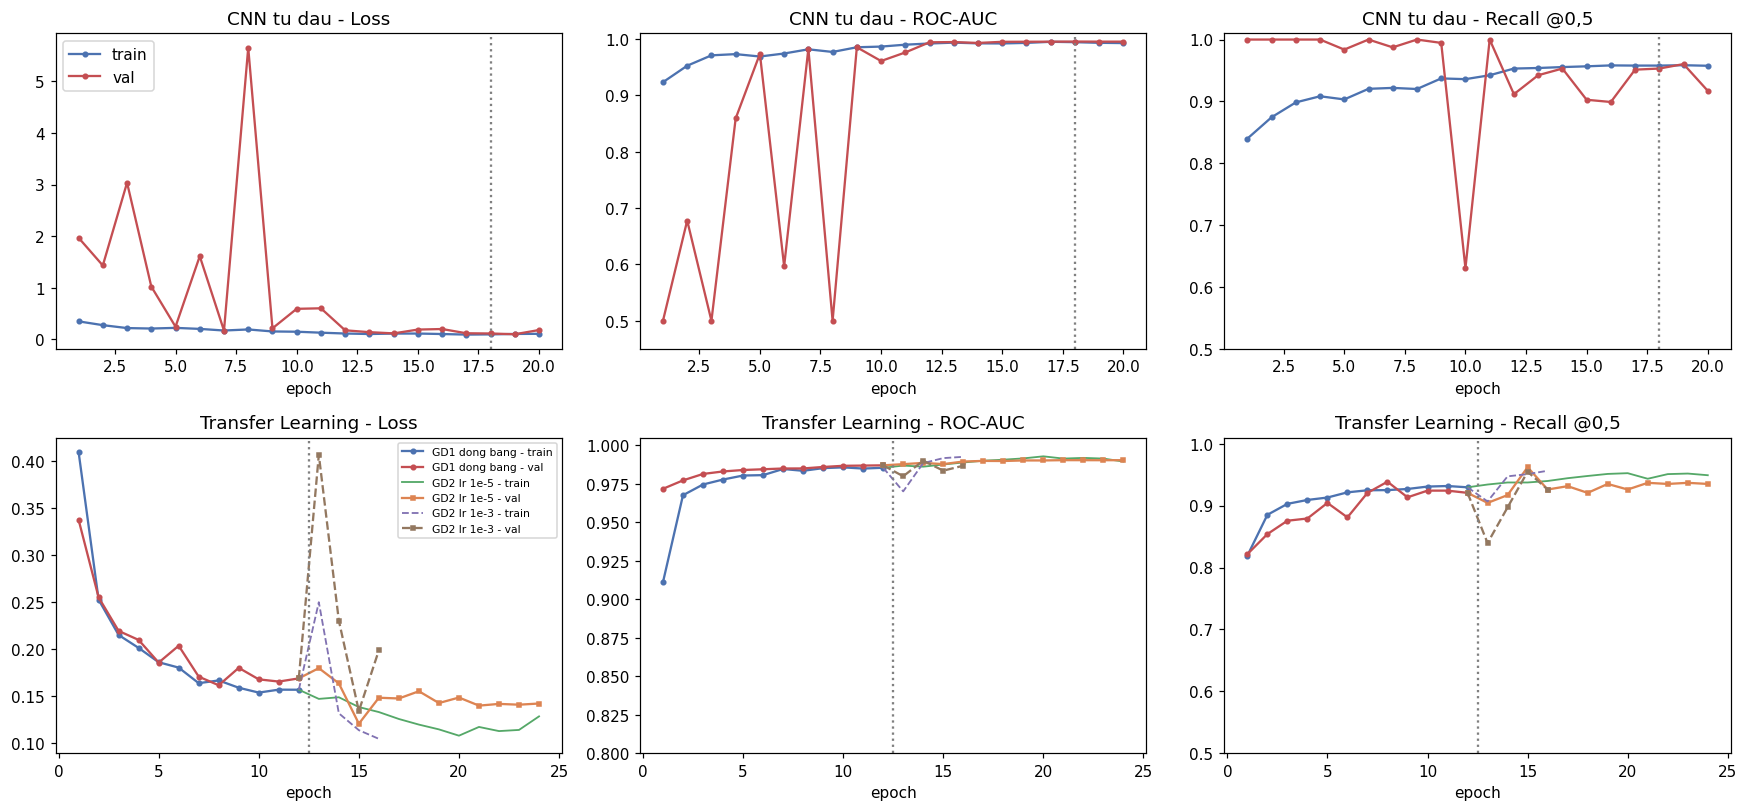

In [8]:
T.plot_learning_curves(runs)
display(Image(R / "learning_curves.png"))

**Đọc kết quả:**

* **CNN từ đầu:** loss train mượt, loss val có các gai lớn (tới 5,7) ở epoch 3, 6, 8 rồi êm hẳn sau khi lr giảm từ
  epoch 10. Đây là hình mẫu của BatchNorm + lr lớn, không phải overfit.
* **Transfer Learning:** giai đoạn 1 tiến mượt và bão hoà sau ~8 epoch. Giai đoạn 2 lr 1e-5 (cam) kéo loss val xuống
  thêm (0,17 → 0,14). Đối chứng lr 1e-3 (nâu, nét đứt) có gai loss ngay tại chỗ chuyển giai đoạn.
* Ở hàng trên, **recall @0,5 trên val bằng 1,0** ở nhiều epoch đầu là vì mô hình đoán *mọi* ảnh là PNEUMONIA (cùng lúc
  với AUC = 0,5). Đây là lý do không dùng recall làm tiêu chí EarlyStopping.

## 9. Chọn mô hình và chọn ngưỡng đạt recall ≥ 0,97 trên val

**Logic code (`choose_threshold`, `compare_models`):**

```python
fpr, tpr, thr = roc_curve(y_val, p_val)
nguong = thr[np.flatnonzero(tpr >= 0.97)[0]]   # nguong CAO NHAT van giu recall val >= 0,97
                                                 # (cao nhat = it bao dong gia nhat)
mo_hinh_chon = argmax(AUC val)                  # khong nhin test
```

Bảng dưới có cả số test để **báo cáo**. Mô hình và ngưỡng được chọn chỉ bằng cột val.

In [9]:
table, best = T.compare_models(runs, data)
final = runs[best]
T.save_final_model(final)
print("Mo hinh chon theo AUC val:", T.NAMES[best], "| nguong:", round(final["nguong"], 4))
table

[save] cnn_tu_dau -> models/best_model.keras (nguong 0.1879)


Mo hinh chon theo AUC val: CNN tu dau (3 khoi Conv) | nguong: 0.1879


,mo_hinh,tham_so,tham_so_train_duoc,so_epoch,thoi_gian_phut,auc_val,nguong_val,specificity_val,auc_test,recall_test_0.5,accuracy_test_0.5,recall_test,specificity_test,accuracy_test,bo_sot_test,bao_dong_gia_test
0,CNN tu dau (3 khoi Conv),288481,287585,20,56.9883,0.9955,0.1879,0.9585,0.9580,0.9846,0.8814,0.9974,0.5043,0.8125,1,116
1,EfficientNetB0 dong bang,4050852,1281,12,28.3233,0.9870,0.2224,0.8964,0.9463,0.9692,0.8542,0.9897,0.4658,0.7933,4,125
2,EfficientNetB0 fine-tune (lr 1e-5),4050852,1484641,12,33.7400,0.9902,0.2550,0.9275,0.9565,0.9795,0.8574,0.9923,0.5470,0.8253,3,106
3,EfficientNetB0 fine-tune lr 1e-3 (doi chung),4050852,1484641,4,6.3833,0.9926,0.0215,0.9223,0.9596,0.9462,0.8926,0.9974,0.4359,0.7869,1,132


**Đọc kết quả:**

| Mô hình | Tham số train | Thời gian | AUC val | Ngưỡng | Specificity val | AUC test | Recall test | Bỏ sót | Báo động giả | Accuracy test |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| **CNN từ đầu** ← chọn | 287.585 | 57 ph | **0,9955** | 0,188 | **0,959** | **0,958** | **0,997** | **1** | 116 | 0,813 |
| EfficientNetB0 đóng băng | 1.281 | 28 ph | 0,9870 | 0,222 | 0,896 | 0,946 | 0,990 | 4 | 125 | 0,793 |
| EfficientNetB0 fine-tune lr 1e-5 | 1.484.641 | 34 ph | 0,9902 | 0,255 | 0,927 | 0,957 | 0,992 | 3 | **106** | **0,825** |
| *(đối chứng lr 1e-3)* | 1.484.641 | 6 ph | 0,9926 | 0,022 | 0,922 | 0,960 | 0,997 | 1 | 132 | 0,787 |

* **CNN từ đầu thắng trên val** ở cả AUC lẫn specificity, nên được chọn. Kết quả này **ngược với giả định** của đề
  ("train từ đầu với 5.000 ảnh → gần như chắc chắn overfit"). Mạng nhỏ (288k tham số), có BN + augmentation +
  GlobalAveragePooling thì không overfit. Còn đặc trưng ImageNet không khớp hoàn toàn với ảnh X-quang xám.
* Trên test, CNN từ đầu và fine-tune **gần như hoà** (AUC 0,958 / 0,957): chênh 3 điểm bằng 1 ca bỏ sót ít hơn nhưng
  10 báo động giả nhiều hơn. Thứ tự đúng như đề dự đoán: đóng băng < fine-tune.
* Đối chứng lr 1e-3 có AUC val cao bất ngờ (0,993) nhưng **ngưỡng phải hạ xuống 0,02** để đạt recall 0,97, dấu hiệu xác
  suất bị lệch mạnh sau cú sốc lr lớn.
* ⚠️ Mọi mô hình đều có **specificity test ~0,44–0,55**, so với 0,90–0,96 trên val. Đây là vấn đề 3 (phân phối train ≠
  test) hiện ra thành số liệu: xem bước 10.

## 10. Đánh giá trên TEST (1 lần): ma trận nhầm lẫn và số ca bỏ sót

**Logic code (`evaluate_test`):** ma trận nhầm lẫn của mô hình đã chọn ở 2 ngưỡng (0,5 mặc định và ngưỡng chọn trên
val). Thêm tỉ lệ dự đoán PNEUMONIA theo tác nhân (lấy từ tên file).

,nguong,recall,specificity,precision,accuracy,bo_sot_FN,bao_dong_gia_FP,TP,TN
0,0.5000,0.9846,0.7094,0.8496,0.8814,6,68,384,166
1,0.1879,0.9974,0.5043,0.7703,0.8125,1,116,389,118


,so_anh,du_doan_PNEUMONIA,ti_le_du_doan_PNEUMONIA,xac_suat_TB
tac_nhan,,,,
bacteria,242.0000,241.0000,0.9959,0.9687
normal,234.0000,116.0000,0.4957,0.3218
virus,148.0000,148.0000,1.0000,0.9426


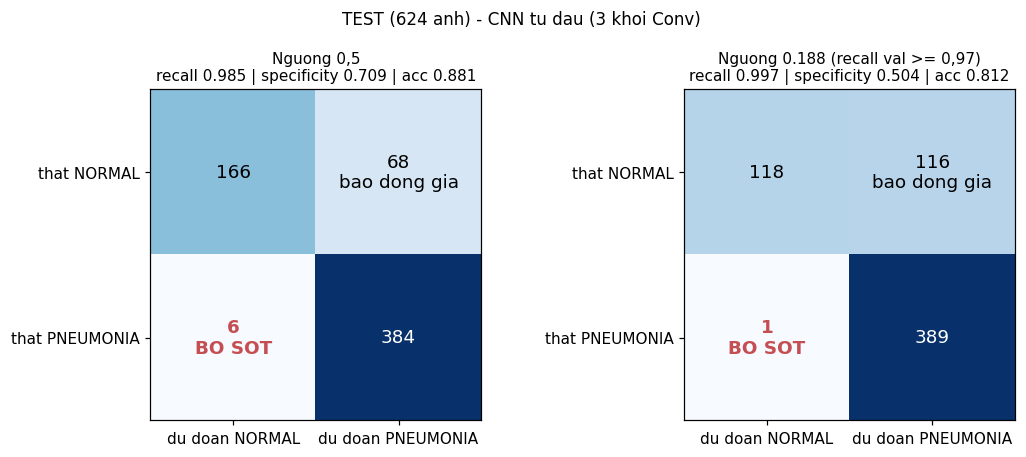

In [10]:
test, by = T.evaluate_test(final, data)
display(test)
display(by)
display(Image(R / "confusion_matrix.png"))

**Đọc kết quả (CNN từ đầu, 624 ảnh test: 234 NORMAL, 390 PNEUMONIA):**

| Ngưỡng | Recall | **Bỏ sót (FN)** | Báo động giả (FP) | Specificity | Precision | Accuracy |
|---|---:|---:|---:|---:|---:|---:|
| 0,5 (mặc định) | 0,985 | **6** | 68 | 0,709 | 0,850 | 0,881 |
| **0,188 (recall val ≥ 0,97)** | **0,997** | **1** | 116 | 0,504 | 0,770 | 0,813 |

* ✅ **Recall test 0,997 ≥ 0,96.** Trong 390 ca viêm phổi, **chỉ bỏ sót 1 ca** (`person154_bacteria_728.jpeg`). Vi
  khuẩn: 241/242 được gắn cờ. Virus: 148/148.
* Cái giá: **116 / 234 phim bình thường bị báo động giả** (50%). Với mục đích "sắp thứ tự đọc phim" thì chấp nhận được:
  bác sĩ trực xem 505 phim gắn cờ trước, 119 phim còn lại xem sau, và trong 119 phim đó chỉ có 1 ca viêm phổi.
* **Accuracy 0,81 thấp hơn mức tham chiếu 0,88–0,93** của đề. Ở ngưỡng 0,5 accuracy là 0,881 (vừa chạm mức tham chiếu)
  nhưng bỏ sót 6 ca. Đánh đổi 5 ca bỏ sót lấy 48 báo động giả là đúng ưu tiên của bài toán.
* **Vì sao specificity tụt từ 0,96 (val) xuống 0,50 (test)?** Phim NORMAL ở test khác phim NORMAL ở train: xác suất
  PNEUMONIA trung vị của phim NORMAL là **0,002 ở val** nhưng **0,18 ở test** (gấp ~100 lần). Nhóm `NORMAL2-IM-*` (165/234 phim NORMAL
  test) bị báo động giả 53%, nhóm `IM-*` 41%. Cả 4 mô hình đều bị như nhau, nên đây là **lệch phân phối của bộ dữ liệu**
  (đề đã cảnh báo ở vấn đề 3), không phải lỗi riêng của một mô hình. Hệ quả thực tế: **ngưỡng chọn trên val không giữ
  được specificity ở dữ liệu mới**. Khi triển khai ở bệnh viện khác, phải hiệu chỉnh lại ngưỡng trên dữ liệu tại chỗ.

## 11. ⭐ Grad-CAM: model nhìn vào đâu?

**Logic code (`model.grad_cam`):**

```python
with tf.GradientTape() as tape:
    A = features(x)                       # ban do dac trung cuoi: 14x14x128 (CNN tu dau), 7x7x1280 (EfficientNet)
    p = Dense(GAP(A))                     # xac suat PNEUMONIA
w   = mean(dp/dA, theo khong gian)        # moi kenh quan trong bao nhieu
cam = ReLU(sum_k w_k * A_k) -> chuan hoa [0,1] -> phong to 224x224
```

Vẽ 6 ca test (2 viêm phổi do vi khuẩn, 1 do virus, 2 bình thường, ca bỏ sót duy nhất) cho mô hình đã chọn và cho
EfficientNet fine-tune để so sánh. Sau đó **định lượng trên cả 624 ảnh test**: tỉ lệ "năng lượng" CAM nằm ở **viền ảnh**
(dải 12% mỗi cạnh, chỗ có chữ R, tên máy, giờ chụp) và ở **4 góc**. Nếu CAM phân bố đều thì viền chiếm 42% diện tích,
4 góc 5,8%.

,mo_hinh,ti_le_o_vien,ti_le_4_goc,dien_tich_vien,dien_tich_4_goc,so_anh_dinh_CAM_o_vien
0,CNN tu dau (3 khoi Conv),0.2540,0.0349,0.4240,0.0581,0.2115
1,EfficientNetB0 fine-tune (lr 1e-5),0.4954,0.0627,0.4240,0.0581,0.6362


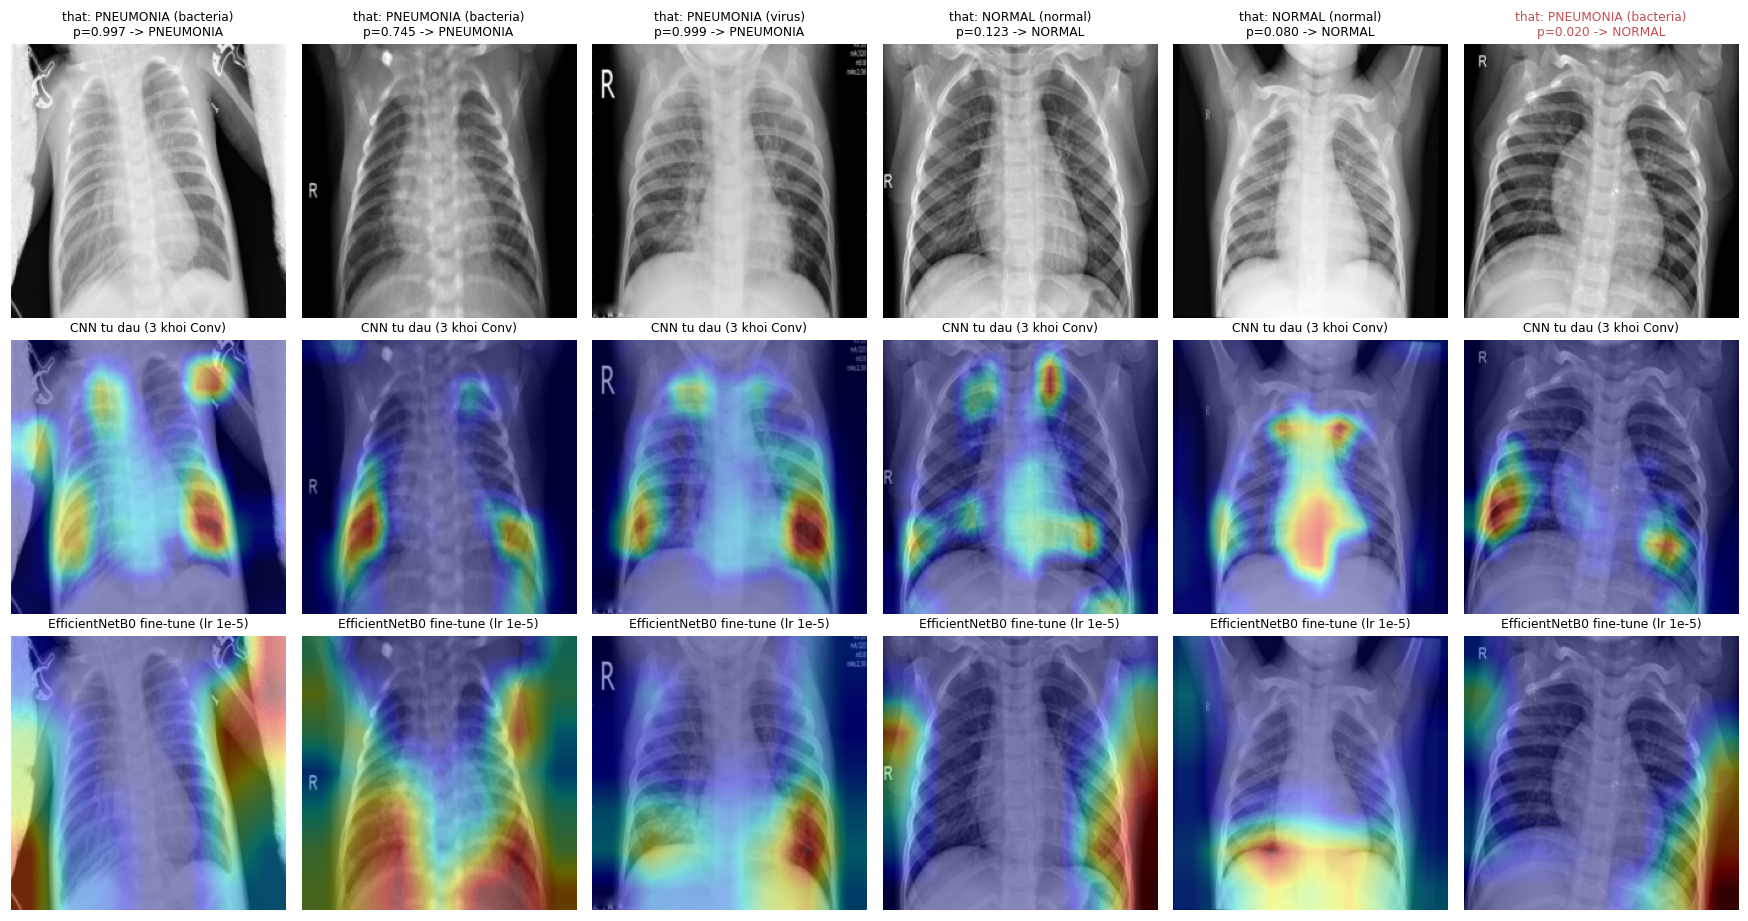

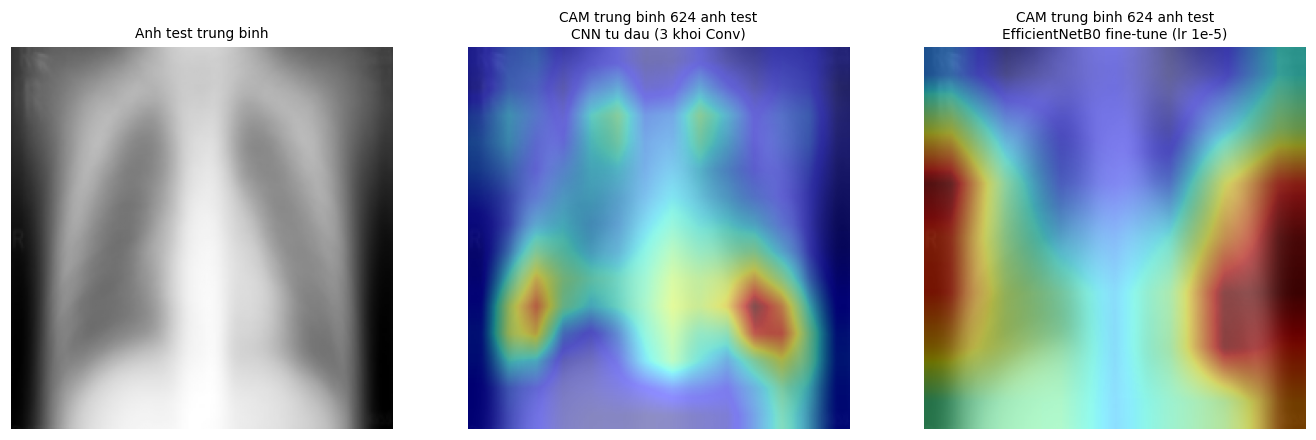

In [11]:
other = runs["tl_finetune"] if best == "cnn_tu_dau" else runs["cnn_tu_dau"]
cam = T.run_gradcam(final, other, data)
display(cam)
display(Image(R / "gradcam_examples.png"))
display(Image(R / "gradcam_trung_binh.png"))

**Đọc kết quả:**

| Mô hình | Năng lượng CAM ở viền (diện tích 42%) | Ở 4 góc (diện tích 5,8%) | % ảnh có đỉnh CAM ở viền |
|---|---:|---:|---:|
| **CNN từ đầu** | **25%** | 3,5% | **21%** |
| EfficientNetB0 fine-tune | 50% | 6,3% | 64% |

* **CNN từ đầu nhìn vào phổi.** CAM trung bình tập trung ở **phế trường dưới hai bên**, nơi viêm phổi ở trẻ em
  hay đông đặc nhất, và ít hơn hẳn mức phân bố đều ở viền/góc. Trên từng ca: phim viêm phổi sáng ở vùng mờ trong phổi.
  Phim bình thường sáng ở trung thất/bóng tim (vùng "không có gì bất thường" để chú ý). **Không ca nào sáng ở chữ "R",
  giờ chụp hay mã máy**, nên model không "gian lận" bằng ký hiệu trên phim.
* **EfficientNet fine-tune đáng lo hơn.** CAM trung bình nằm ở **thành ngực hai bên và phần bụng**, phía ngoài phổi. 64%
  ảnh có điểm nóng nhất ở viền. Một phần do CAM của EfficientNet chỉ có 7×7 ô (mỗi ô ~32 px, nên rất thô). Nhưng xu
  hướng vẫn rõ: model dùng hình dạng thành ngực/mô mềm (có thể liên quan tuổi, cỡ người, tư thế chụp) nhiều hơn nhu mô
  phổi. Đây là lý do thứ hai, bên cạnh AUC val, để **không** chọn nó. Hai model có AUC test bằng nhau nhưng chỉ một
  model nhìn đúng chỗ.
* Ca bỏ sót (cột 6): CNN chú ý đúng phế trường dưới hai bên nhưng không thấy gì bất thường (xác suất 0,02). Xem bước 12.

## 12. 10 ca dự đoán sai

**Logic code (`show_errors`):** ở ngưỡng đã chọn, lấy **tất cả** ca bỏ sót (FN, ở đây chỉ 1), rồi các ca báo động giả
(FP) mà model **tự tin nhất** (xác suất cao nhất). Phủ Grad-CAM lên mỗi ảnh.

,file,lop_that,tac_nhan,xac_suat_PNEUMONIA,loai_sai
0,person154_bacteria_728.jpeg,PNEUMONIA,bacteria,0.0202,FN bo sot
1,IM-0022-0001.jpeg,NORMAL,normal,1.0000,FP bao dong gia
2,NORMAL2-IM-0256-0001.jpeg,NORMAL,normal,0.9999,FP bao dong gia
3,NORMAL2-IM-0252-0001.jpeg,NORMAL,normal,0.9996,FP bao dong gia
4,NORMAL2-IM-0210-0001.jpeg,NORMAL,normal,0.9977,FP bao dong gia
5,NORMAL2-IM-0198-0001.jpeg,NORMAL,normal,0.9953,FP bao dong gia
6,NORMAL2-IM-0219-0001.jpeg,NORMAL,normal,0.9949,FP bao dong gia
7,NORMAL2-IM-0373-0001.jpeg,NORMAL,normal,0.9943,FP bao dong gia
8,NORMAL2-IM-0246-0001.jpeg,NORMAL,normal,0.9886,FP bao dong gia
9,NORMAL2-IM-0249-0001.jpeg,NORMAL,normal,0.9883,FP bao dong gia


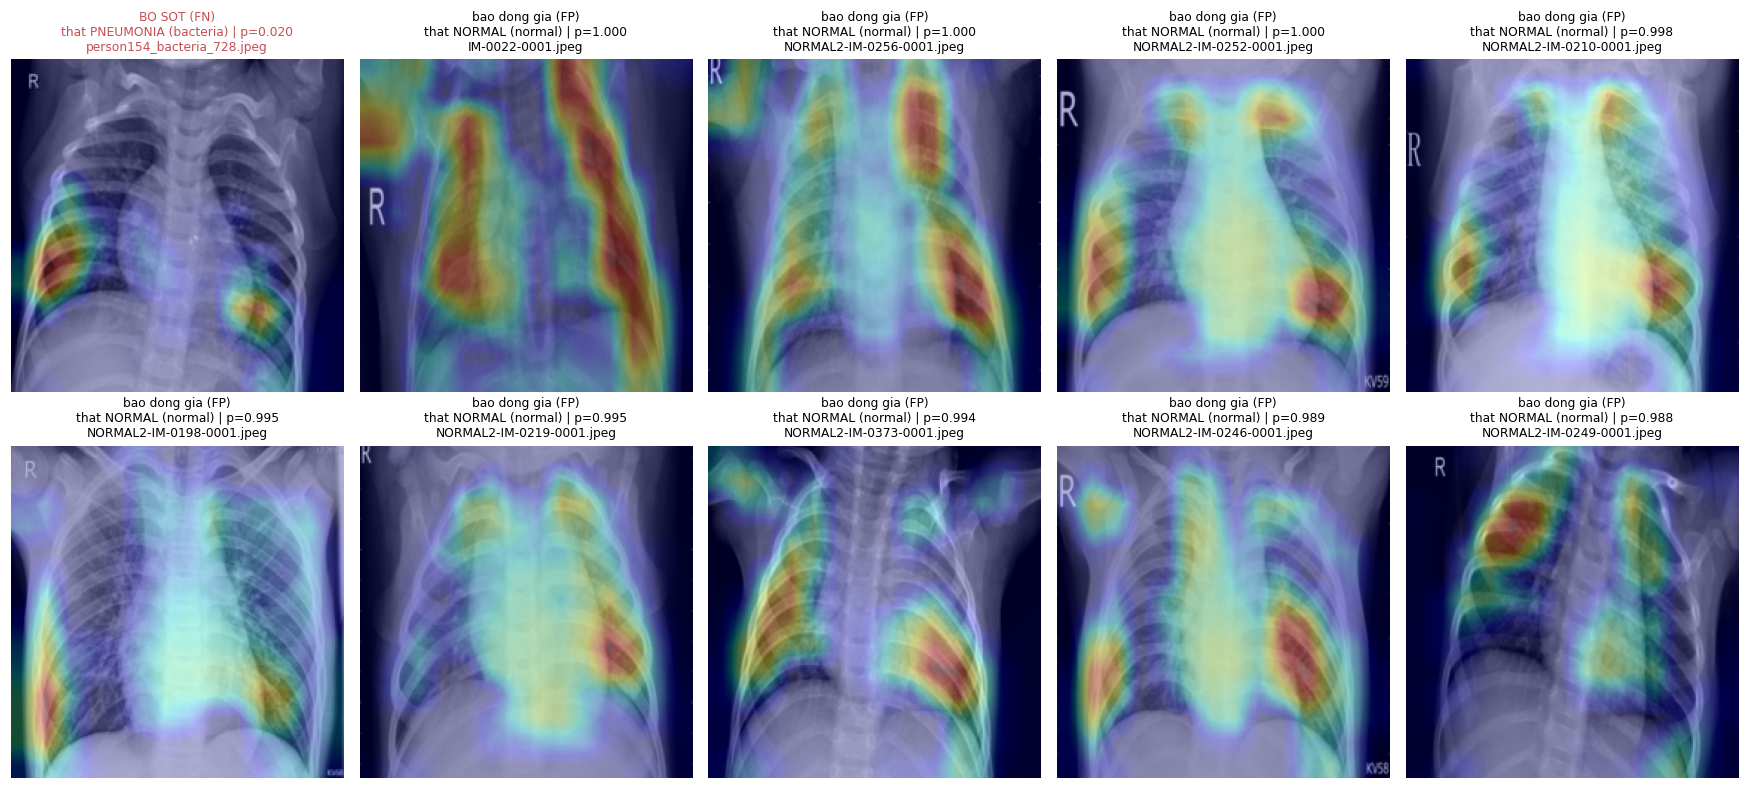

[save] reports/tom_tat.json


In [12]:
errs = T.show_errors(final, data)
display(errs)
display(Image(R / "ca_du_doan_sai.png"))
T.save_summary(so_luong_anh=counts.reset_index(), chia_du_lieu=D.split_table(data["df"]).reset_index(),
               so_sanh=table, mo_hinh_chon=best, nguong=final["nguong"], test=test,
               test_theo_tac_nhan=by.reset_index(), gradcam=cam, ca_sai=errs)

**Đọc kết quả:**

| # | Ca | Xác suất | Nhận xét |
|---|---|---:|---|
| 1 | **BỎ SÓT** `person154_bacteria_728` | 0,020 | Xem cả ảnh gốc: hai phế trường vẫn **đen, thông khí tốt**, không thấy đông đặc rõ. Phim hơi xoay. Tổn thương có thể rất nhỏ, hoặc **nhãn bị nhiễu** (bộ này có nhãn sai đã được ghi nhận). Mô hình ra 0,02, tức rất tự tin là bình thường |
| 2 | FP `IM-0022-0001` | 1,000 | Phim **xám đục toàn bộ, tương phản rất thấp**: phổi không đen như phim bình thường điển hình, trông giống mờ lan toả |
| 3–10 | FP `NORMAL2-IM-*` (8 ca) | 0,988–1,000 | Đa số là phim **mờ / tương phản thấp**, hoặc có **vân phổi đậm** (mạch máu, phế quản rõ). CAM sáng ở phế trường dưới, tức đúng vùng, nhưng vùng đó trông "đục" giống thâm nhiễm. `NORMAL2-IM-0198` có cả giờ chụp và mã `KV68` ở góc, nhưng CAM **không** nằm ở đó |

* **Nguyên nhân chính của báo động giả là chất lượng / độ tương phản của phim**, không phải đường tắt: phim mờ làm phổi
  bình thường trông đục giống thâm nhiễm. Với trẻ 1–5 tuổi (khó nằm yên, khó nín thở), phim chụp kém rất phổ biến.
* 9/10 ca sai là `NORMAL2-IM-*`, phù hợp với nhóm này chiếm 71% NORMAL test và có tỉ lệ báo động giả cao hơn (53% so
  với 41%).
* **Ca bỏ sót duy nhất không có dấu hiệu bất thường rõ**, kể cả ở ảnh gốc. Hướng giảm bỏ sót tiếp theo: tăng độ phân giải đầu vào
  (vd 384–512), hoặc chuyển các ca có xác suất trung gian sang bác sĩ ngay (MC Dropout, mở rộng 3 của đề).

## Kết luận

1. **Đạt yêu cầu:** recall test **0,997** (≥ 0,96), **1 ca bỏ sót** / 390 ca viêm phổi, 116 báo động giả / 234 phim bình
   thường. Mô hình: CNN 3 khối tự xây, ngưỡng 0,188 (`models/best_model.keras` + `models/nguong.json`).
2. **CNN từ đầu không thua Transfer Learning** ở bài này: AUC val 0,995 so với 0,990, AUC test hoà (0,958 / 0,957), và
   Grad-CAM cho thấy nó nhìn vào phổi tốt hơn. Đổi lại train chậm hơn (57 so với 28 + 34 phút) và đường học rất bất ổn
   ở lr lớn. Transfer Learning cho kết quả tốt ngay epoch đầu và ổn định, đúng như đề nói.
3. **Fine-tune lr 1e-5 > đóng băng** (+0,003 AUC val, +0,011 AUC test, bỏ sót 3 so với 4). lr 1e-3 gây sốc rõ (val loss
   x2,4) nhưng không phá huỷ hẳn, vì BN bị khoá và chỉ mở 30 lớp.
4. **Lệch phân phối là rủi ro lớn nhất:** specificity 0,96 trên val chỉ còn 0,50 trên test. Ngưỡng phải được hiệu chỉnh
   lại trên dữ liệu của nơi triển khai.

> 🩺 **CẢNH BÁO Y TẾ:** công cụ **sắp thứ tự ưu tiên đọc phim**, không phải công cụ chẩn đoán. Dữ liệu từ một bệnh
> viện ở Quảng Châu, bệnh nhi 1–5 tuổi, nên **không tổng quát hoá** cho người lớn hay dân số khác. Mọi phim, kể cả phim
> không bị gắn cờ, đều phải có bác sĩ đọc lại.